# 🍽️ FoodVision101: Klasyfikacja obrazów z użyciem transfer learningu

**FoodVision101** koncentruje się na klasyfikacji obrazów jedzenia z wykorzystaniem transfer learningu w TensorFlow.
Celem tego projektu jest wykorzystanie mocy wcześniej wytrenowanych konwolucyjnych sieci neuronowych (CNN), aby rozpoznawać i kategoryzować różne potrawy z [zestawu danych Food101](https://data.vision.ee.ethz.ch/cvl/datasets_extra/food-101/), zawierającego **101 kategorii dań**.

W projekcie korzystam z **10% zestawu danych Food101** (tylko 75 obrazów per klasa w zbiorze treningowym i 250 obrazów per klasa w zbiorze testowym). Dzięki transfer learningowi możemy efektywnie trenować model na tym zbiorze, dostosowując wcześniej wytrenowaną sieć (taką jak EfficientNet lub ResNet), zamiast trenować model od zera.

---

### 🎯 Główne cele

- 📊 **Eksploracja i wstępne przetwarzanie** danych Food101 z użyciem wydajnych pipeline’ów TensorFlow.
- 🧠 **Budowa i dostrajanie** modelu transfer learningowego do klasyfikacji obrazów wieloklasowych.
- 🧪 **Ocena wydajności** na oficjalnym zestawie testowym Food101.
- 🖼️ **Testowanie modelu** na własnych zdjęciach jedzenia w celu sprawdzenia działania w rzeczywistych warunkach.

---

Ten projekt jest częścią moich studiów z zakresu **Data Science** i pokazuje praktyczne umiejętności z obszaru uczenia maszynowego w kontekście computer vision, przetwarzania danych i wdrażania modeli.


In [1]:
import importlib
import helper_functions
importlib.reload(helper_functions)
import os
import random
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'

from helper_functions import plot_loss_curves, compare_historys, walk_through_dir, unzip_data, plot_random_images_from_directory, plot_augmented_image, make_confusion_matrix, load_and_prep_image
import tensorflow as tf
import pandas as pd
from tensorflow.keras import layers
from tensorflow.keras.layers.experimental import preprocessing
from tensorflow.keras.models import Sequential
from tqdm.keras import TqdmCallback
from sklearn.metrics import classification_report
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid")

## 📦 Przygotowanie zbioru danych

Zanim rozpocznę trenowanie modelu, muszę pobrać **zestaw danych Food101** (wersja 10%) z zewnętrznego źródła.
Poniższe polecenie pobierze plik ZIP zawierający dane, które następnie zostaną rozpakowane i uporządkowane w katalogach treningowym i testowym.

In [2]:
zip_file = '101_food_classes_10_percent.zip'

if not os.path.exists(zip_file):
    print(f"{zip_file} not found. Downloading...")
    url = 'https://storage.googleapis.com/ztm_tf_course/food_vision/101_food_classes_10_percent.zip'
    get_ipython().system(f"wget {url} -O {zip_file}")
    print(f"{zip_file} downloaded")
else:
    print(f"{zip_file} already exists")

unzip_data("101_food_classes_10_percent.zip")

train_dir = "101_food_classes_10_percent/train/"
test_dir = "101_food_classes_10_percent/test/"

101_food_classes_10_percent.zip not found. Downloading...
--2025-05-10 12:56:04--  https://storage.googleapis.com/ztm_tf_course/food_vision/101_food_classes_10_percent.zip
Resolving storage.googleapis.com (storage.googleapis.com)... 2a00:1450:401b:800::201b, 2a00:1450:401b:806::201b, 2a00:1450:401b:808::201b, ...
Connecting to storage.googleapis.com (storage.googleapis.com)|2a00:1450:401b:800::201b|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 1625420029 (1.5G) [application/zip]
Saving to: ‘101_food_classes_10_percent.zip’

101_food_classes_10 100%[===================>]   1.51G  24.6MB/s    in 65s     

2025-05-10 12:57:09 (24.0 MB/s) - ‘101_food_classes_10_percent.zip’ saved [1625420029/1625420029]

101_food_classes_10_percent.zip downloaded


## 📂 Eksploracja struktury zbioru danych

Zanim rozpocznę trenowanie modelu, warto zrozumieć strukturę naszego zbioru danych.
Użyję stworzonej przeze mnie funkcji `walk_through_dir`, aby sprawdzić katalog i upewnić się, że obrazy są poprawnie uporządkowane w podkatalogach — każdy podkatalog odpowiada jednej klasie jedzenia.

Funkcja wyświetli liczbę obrazów w każdym katalogu klas, co pozwoli nam zweryfikować zbiór danych.
Oto szybki podgląd struktury katalogów:


In [3]:
walk_through_dir("101_food_classes_10_percent")

There are 2 directories and 0 images in '101_food_classes_10_percent'.
There are 101 directories and 0 images in '101_food_classes_10_percent/test'.
There are 0 directories and 250 images in '101_food_classes_10_percent/test/foie_gras'.
There are 0 directories and 250 images in '101_food_classes_10_percent/test/club_sandwich'.
There are 0 directories and 250 images in '101_food_classes_10_percent/test/cheese_plate'.
There are 0 directories and 250 images in '101_food_classes_10_percent/test/cup_cakes'.
There are 0 directories and 250 images in '101_food_classes_10_percent/test/garlic_bread'.
There are 0 directories and 250 images in '101_food_classes_10_percent/test/gnocchi'.
There are 0 directories and 250 images in '101_food_classes_10_percent/test/ice_cream'.
There are 0 directories and 250 images in '101_food_classes_10_percent/test/samosa'.
There are 0 directories and 250 images in '101_food_classes_10_percent/test/donuts'.
There are 0 directories and 250 images in '101_food_class

## 🗂️ Przygotowanie danych wejściowych

Ustawiam rozmiar obrazu na **300x300** pikseli, co jest standardem dla wcześniej wytrenowanego modelu EfficientNetV2B3, którego zamierzam użyć.
Korzystając z funkcji `image_dataset_from_directory` z biblioteki TensorFlow, ładuję zestawy danych treningowych i testowych z określonych katalogów.

- Dane `train_data` są ładowane z etykietami w formacie **kategorycznym** (one-hot encoding).
- Dane `test_data` są ładowane w podobny sposób, ale ustawiamy `shuffle=False`, aby zachować kolejność danych testowych — co jest istotne podczas oceny modelu i analizy predykcji.

To przygotowuje dane do trenowania i oceny modelu. 🧑‍🍳📸


In [4]:
# Ustawienie danych wejściowych
IMG_SIZE = (300, 300)
train_data = tf.keras.preprocessing.image_dataset_from_directory(train_dir,
                                                                 label_mode="categorical",
                                                                 image_size=IMG_SIZE)
test_data = tf.keras.preprocessing.image_dataset_from_directory(test_dir,
                                                                label_mode="categorical",
                                                                image_size=IMG_SIZE,
                                                                shuffle=False) # nie mieszam danych testowych podczas analizy prognoz

Found 7575 files belonging to 101 classes.
Found 25250 files belonging to 101 classes.


### 🔍 Wizualna inspekcja surowych obrazów

Aby lepiej zrozumieć zbiór danych, stworzyłem funkcję, która losowo wybiera i wyświetla 9 obrazów z różnych folderów klas.
Pomaga to zobaczyć różnorodność i jakość danych przed rozpoczęciem trenowania modelu.

Found 7575 files belonging to 101 classes.


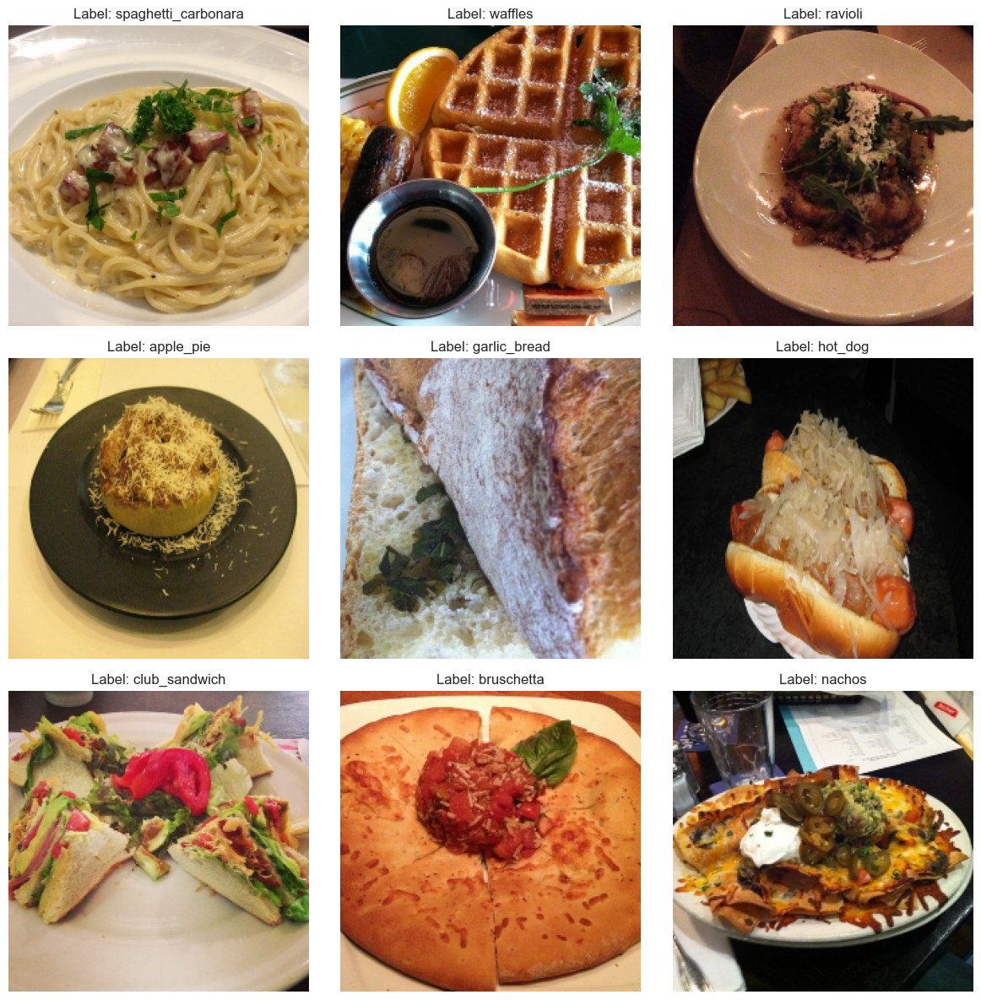

In [5]:
plot_random_images_from_directory("101_food_classes_10_percent/train/")

## 🛠️ Trenowanie modelu z użyciem transfer learningu

Oto kroki, które podejmę:

* Utworzenie callbacku `ModelCheckpoint`
* Dodanie warstwy augmentacji danych, aby wbudować augmentację bezpośrednio w model
* Zbudowanie modelu w oparciu o EfficientNetV2B3 w trybie „headless” (bez górnych warstw) przy użyciu funkcjonalnego API (dodam własną warstwę wyjściową)
* Kompilacja modelu
* Ekstrakcja cech przez 5 pełnych epok (5 przejść przez zbiór treningowy i walidacja na 20% danych testowych)

In [6]:
# Tworzenie checkpoint callback
checkpoint_path = "FoodVision101_model_checkpoint"
checkpoint_callback = tf.keras.callbacks.ModelCheckpoint(checkpoint_path,
                                                         save_weights_only=True,
                                                         monitor='val_accuracy',
                                                         save_best_only=True)

### 🔄 Tworzenie warstwy augmentacji danych

Aby pomóc modelowi lepiej uogólniać i być bardziej odpornym na zmienność danych wejściowych, tworzę warstwę augmentacji danych z wykorzystaniem warstw wstępnego przetwarzania TensorFlow.
Warstwa ta wykonuje losowe transformacje, takie jak obracanie, przybliżanie i przesuwanie obrazów — wszystko to odbywa się dynamicznie podczas trenowania, bezpośrednio w ramach pipeline'u modelu.

In [7]:
# Tworzenie warstwy augmentacji danych
data_augmentation = Sequential([
    preprocessing.RandomFlip("horizontal"),
    preprocessing.RandomRotation(0.2),
    preprocessing.RandomZoom(0.2),
    preprocessing.RandomHeight(0.2),
    preprocessing.RandomWidth(0.2),
    preprocessing.RandomContrast(factor=0.1)
], name='data_augmentation')

### 🖼️ Przykład: obraz oryginalny vs. obraz po augmentacji

Poniżej znajduje się wizualny przykład pokazujący, jak warstwa augmentacji danych przekształca obraz wejściowy podczas trenowania.

**Original Image** przedstawia dane wejściowe w takiej formie, w jakiej występują w zbiorze danych – bez żadnych modyfikacji.

**Augmented Image** to wynik zastosowania serii losowych transformacji zdefiniowanych w pipeline'ie augmentacyjnym. Obejmują one:

- **Losowe odbicie w poziomie** – symuluje lustrzane odbicie, przydatne w przypadku obiektów symetrycznych, takich jak jedzenie.
- **Losową rotację** – obraca obraz o losowy, niewielki kąt, dzięki czemu model staje się odporny na zmianę orientacji.
- **Losowe przybliżenie (zoom)** – przybliża obraz w sposób losowy, co pomaga modelowi rozpoznawać obiekty w różnych skalach.
- **Losowe przesunięcia w pionie i poziomie** – przesuwa obraz w górę, dół lub na boki, umożliwiając modelowi lepsze radzenie sobie ze zmiennością położenia.

Te transformacje są stosowane **tylko podczas trenowania** i są różne w każdej epoce, co sprawia, że model za każdym razem widzi nieco inną wersję danego obrazu.
Technika ta zwiększa różnorodność danych i pomaga zapobiegać przeuczeniu, zmuszając model do skupienia się na bardziej ogólnych i odpornych cechach zamiast zapamiętywania konkretnych wzorców.

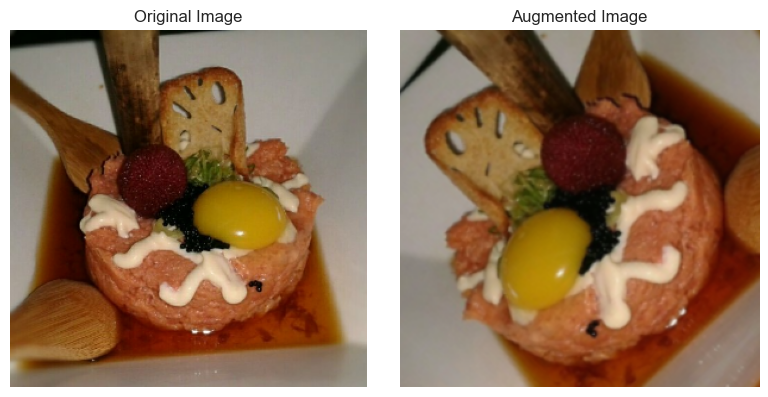

In [8]:
plot_augmented_image(train_data, data_augmentation)

## 🛠️ **Konfiguracja modelu bazowego i architektury**

W tej sekcji konfiguruję **model bazowy**, wykorzystując **EfficientNetV2B3** wytrenowany wcześniej na zbiorze **ImageNet**. Zamrażam warstwy modelu bazowego, aby nie były trenowane podczas etapu fine-tuningu. Następnie dodaję własne **warstwy końcowe** dopasowane do klasyfikacji jedzenia.

1. **Base model**:
   Ładuję **EfficientNetV2B3** bez górnych warstw (`include_top=False`), abym mógł zbudować własne warstwy wyjściowe. Model bazowy ustawiam jako nietrenowalny (`trainable=False`), co powoduje, że jego wagi pozostają zamrożone.

2. **Augmentacja danych**:
   Do obrazów wejściowych stosuję **augmentację danych**, aby wprowadzić różnorodność w trakcie treningu, co pomaga modelowi lepiej się uogólniać.

3. **Architektura modelu**:
   Obrazy po augmentacji przepuszczam przez model bazowy w trybie inferencji (`training=False`), aby warstwy pozostały zamrożone.
   Następnie wynik przechodzi przez warstwę **Global Average Pooling**, która zmniejsza wymiary przestrzenne.
   Na końcu dodaję warstwę wyjściową **Dense** z funkcją aktywacji **softmax**, odpowiadającą liczbie klas w zbiorze danych.

Ta architektura pozwala wykorzystać zalety transfer learningu, jednocześnie dostosowując warstwę wyjściową do klasyfikacji jedzenia.


In [9]:
# Ustawienie modelu bazowego i zamrożenie warstw
base_model = tf.keras.applications.EfficientNetV2B3(include_top=False)
base_model.trainable = False

# Ustawienie architektury modelu z trenowalnymi górnymi warstwami
inputs = layers.Input(shape=(300, 300, 3))
x = tf.keras.applications.efficientnet.preprocess_input(inputs)
x = data_augmentation(x)
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
x = layers.Dense(256, kernel_regularizer=tf.keras.regularizers.l2(0.001))(x)
x = layers.BatchNormalization()(x)
x = layers.Activation("swish")(x)
x = layers.Dropout(0.5)(x)
outputs = layers.Dense(len(train_data.class_names), activation="softmax")(x)
model = tf.keras.Model(inputs, outputs)

In [10]:
model.summary()

Model: "model"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_2 (InputLayer)        [(None, 300, 300, 3)]     0         
                                                                 
 data_augmentation (Sequent  (None, None, None, 3)     0         
 ial)                                                            
                                                                 
 efficientnetv2-b3 (Functio  (None, None, None, 1536   12930622  
 nal)                        )                                   
                                                                 
 global_average_pooling2d (  (None, 1536)              0         
 GlobalAveragePooling2D)                                         
                                                                 
 dropout (Dropout)           (None, 1536)              0         
                                                             

In [11]:
# Compile
model.compile(loss='categorical_crossentropy',
              optimizer=tf.keras.optimizers.legacy.Adam(),
              metrics=['accuracy'])

# Fit
feature_extraction_history = model.fit(train_data,
                                       epochs=5,
                                       validation_data=test_data,
                                       validation_steps=int(0.2 * len(test_data)), # validate on only 20% of test data during training
                                       callbacks=[checkpoint_callback, TqdmCallback()],
                                       verbose=0)

0epoch [00:00, ?epoch/s]

0batch [00:00, ?batch/s]

## 📊 **Ewaluacja modelu na zbiorze testowym**

Po wytrenowaniu modelu, kluczowe jest ocenić jego wydajność na niewidzianych wcześniej danych testowych, aby zrozumieć, jak dobrze model uogólnia się na nowe dane. W tej sekcji używam funkcji `evaluate()`, aby ocenić model na całym zbiorze testowym.

1. **Ewaluacja**:
   Wywołuję `model.evaluate(test_data)`, aby obliczyć **loss** i **accuracy** modelu na zbiorze testowym. Dzięki temu uzyskam wgląd w to, jak model radzi sobie w rzeczywistym scenariuszu.

2. **Wykresy strat**:
   Po ewaluacji wizualizuję **krzywe strat** podczas treningu za pomocą funkcji `plot_loss_curves()`, co pomaga w analizie postępu uczenia się i wykrywaniu przeuczenia lub niedouczenia modelu.


In [12]:
# Ewaluacja na całym zestawie testowym
feature_extraction_results = model.evaluate(test_data)
feature_extraction_results

790/790 [==============================] - 743s 941ms/step - loss: 1.9908 - accuracy: 0.5764


[1.990846037864685, 0.5763564109802246]

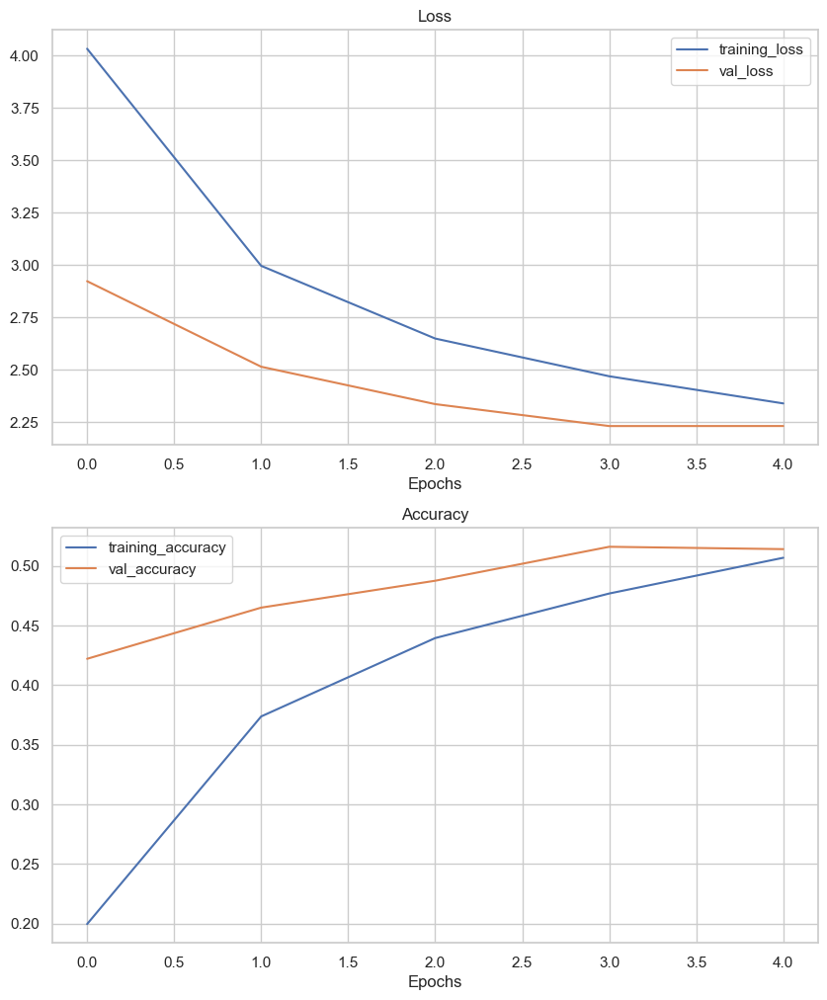

In [13]:
plot_loss_curves(feature_extraction_history)

## 🔧 **Fine-Tuning modelu**

Po wytrenowaniu modelu za pomocą ekstrakcji cech, można jeszcze bardziej poprawić jego wydajność poprzez **fine-tuning** modelu bazowego. Fine-tuning pozwala na dostosowanie wag niektórych warstw w wytrenowanym modelu, co sprawia, że model staje się lepiej dopasowany do konkretnego zadania.

1. **Odblokowanie warstw modelu bazowego**:
   Początkowo model bazowy był zamrożony, aby zapobiec aktualizacji wag podczas treningu. Teraz odblokowuję cały model bazowy, umożliwiając aktualizację wszystkich warstw podczas fine-tuningu.

2. **Ponowne zamrożenie wszystkich warstw oprócz ostatnich 50**:
   Aby uniknąć przeuczenia i zachować nauczone cechy z wcześniejszych warstw, zamrażam wszystkie warstwy modelu bazowego z wyjątkiem ostatnich 50. Dzięki temu model może dostosować cechy wyższego poziomu, nie zakłócając podstawowych cech nauczonych podczas początkowego etapu treningu.

3. **Ponowne kompilowanie modelu**:
   Po modyfikacji warstw, ponownie kompiluję model z **niższym learning rate**, aby dokonywać drobnych poprawek bez drastycznego zmieniania wag wytrenowanych wcześniej. Zmniejszenie współczynnika uczenia pomaga uniknąć zniszczenia wartościowych cech nauczonych przez model w początkowej fazie treningu.

4. **Sprawdzenie trenowalnych warstw**:
   Wylistuję, które warstwy są trenowalne, aby upewnić się, że odpowiednie warstwy są aktualizowane podczas fine-tuningu.

5. **Fine-tuning modelu**:
   Na końcu trenuję model przez dodatkową liczbę epok (np. 5 dodatkowych epok) z niższym learning rate i callbackami do monitorowania. Dzięki temu model może uczyć się nowych cech, zachowując jednocześnie wcześniej wyuczone wzory.


In [14]:
# Odmrożenie wszystkich warstw bazowego modelu
base_model.trainable = True

# Zamrożenie wszystkich oprócz ostatnich 50 warstw
for layer in base_model.layers[:-50]:
    layer.trainable = False

In [15]:
# Recompile modelu z niższym learning
model.compile(loss='categorical_crossentropy',
              optimizer=tf.keras.optimizers.legacy.Adam(learning_rate=0.0001), # learning rate obniżony o 10x
              metrics=['accuracy'])

In [16]:
# Sprawdzenie, które warstwy są trenowalne
for layer_number, layer in enumerate(model.layers[2].layers):
    print(layer_number, layer.name, layer.trainable)

0 input_1 False
1 rescaling False
2 normalization False
3 stem_conv False
4 stem_bn False
5 stem_activation False
6 block1a_project_conv False
7 block1a_project_bn False
8 block1a_project_activation False
9 block1b_project_conv False
10 block1b_project_bn False
11 block1b_project_activation False
12 block1b_drop False
13 block1b_add False
14 block2a_expand_conv False
15 block2a_expand_bn False
16 block2a_expand_activation False
17 block2a_project_conv False
18 block2a_project_bn False
19 block2b_expand_conv False
20 block2b_expand_bn False
21 block2b_expand_activation False
22 block2b_project_conv False
23 block2b_project_bn False
24 block2b_drop False
25 block2b_add False
26 block2c_expand_conv False
27 block2c_expand_bn False
28 block2c_expand_activation False
29 block2c_project_conv False
30 block2c_project_bn False
31 block2c_drop False
32 block2c_add False
33 block3a_expand_conv False
34 block3a_expand_bn False
35 block3a_expand_activation False
36 block3a_project_conv False
37 bl

In [17]:
# Fine-tune przez 5 kolejnych epok
fine_tune_epochs = 10 # model był już trenowany przez 5 epok (feature extraction), 10 to całkowita liczba epok (5 + 5 = 10)

# Fine-tune
fine_tune_history = model.fit(train_data,
                              epochs=fine_tune_epochs,
                              validation_data=test_data,
                              validation_steps=int(0.2 * len(test_data)),
                              initial_epoch=feature_extraction_history.epoch[-1],
                              callbacks=[checkpoint_callback, TqdmCallback()],
                              verbose=0)

0epoch [00:00, ?epoch/s]

0batch [00:00, ?batch/s]

In [18]:
# Ewaluacja na całym zestawie testowym
fine_tune_results = model.evaluate(test_data)
fine_tune_results

790/790 [==============================] - 1106s 1s/step - loss: 1.6099 - accuracy: 0.6706


[1.6099321842193604, 0.6705742478370667]

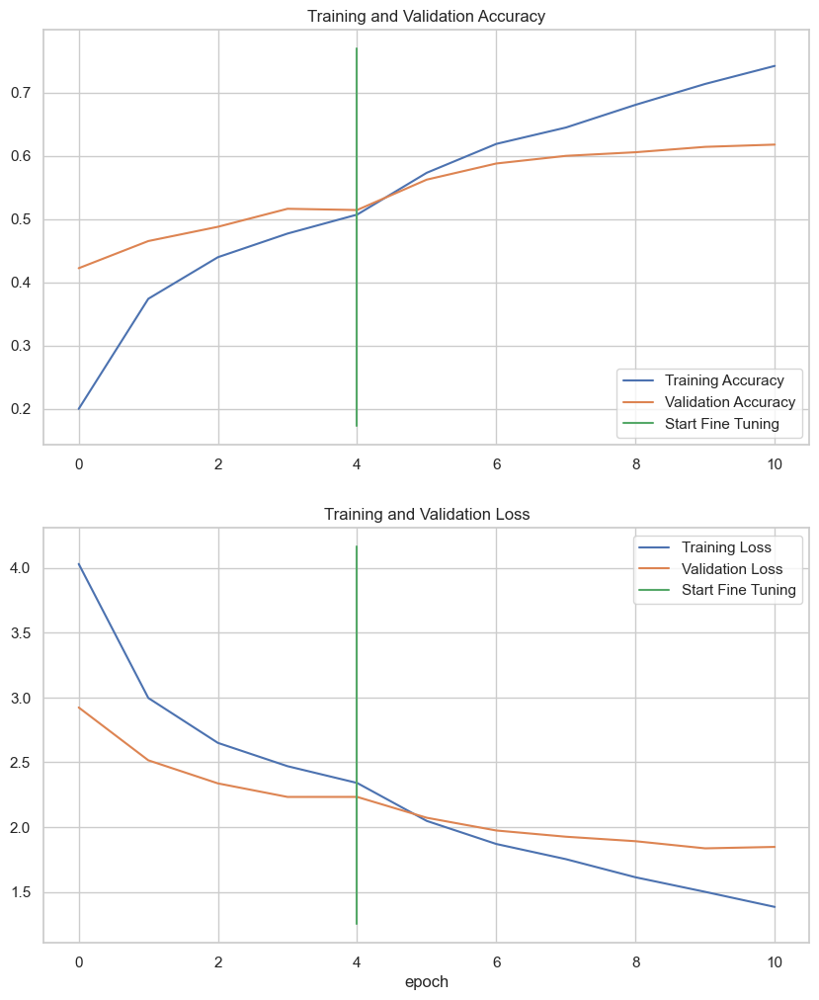

In [19]:
# Porównanie historii feature extraction z fine tuning model
compare_historys(feature_extraction_history,
                 fine_tune_history,
                 initial_epochs=5)

## Saving our model

In [20]:
model.save('models/FoodVision101.h5')

/Users/igorbartkowski/tensorflow-6/env/lib/python3.8/site-packages/keras/src/engine/training.py:3000: UserWarning: You are saving your model as an HDF5 file via `model.save()`. This file format is considered legacy. We recommend using instead the native Keras format, e.g. `model.save('my_model.keras')`.
  saving_api.save_model(


In [21]:
model = tf.keras.models.load_model('models/FoodVision101.h5')

## Ocena wydajności naszego modelu na różnych klasach

Zrobię kilka prognoz, zwizualizuję je, a potem sprawdzę, które prognozy były "najbardziej" błędne.

In [22]:
preds_probs = model.predict(test_data, verbose=1)

790/790 [==============================] - 1169s 1s/step


In [23]:
# Klasy przewidywane dla każdej etykiety
pred_classes = preds_probs.argmax(axis=1)

Teraz, gdy mam wektor prognoz wygenerowanych przez model, aby ocenić jego wydajność, muszę porównać te prognozy z rzeczywistymi etykietami z zestawu testowego.

In [24]:
# Aby uzyskać etykiety testowe, trzeba "rozwinąć" testowy BatchDataset
y_labels = []
for images, labels in test_data.unbatch():
    y_labels.append(labels.numpy().argmax()) # obecnie etykiety testowe wyglądają tak: [0, 0, 0, 1, 0, 0... ], chcemy uzyskać indeks, w którym występuje "1"
y_labels[:20], len(y_labels) # zobaczmy na pierwsze 20

([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], 25250)

### Ocena prognoz naszego modelu

In [25]:
make_confusion_matrix(y_true=y_labels,
                      y_pred=pred_classes,
                      classes=test_data.class_names,
                      figsize=(100, 100),
                      text_size=20)

In [26]:
print(classification_report(y_true=y_labels, y_pred=pred_classes))

              precision    recall  f1-score   support

           0       0.36      0.37      0.37       250
           1       0.52      0.80      0.63       250
           2       0.61      0.76      0.67       250
           3       0.63      0.78      0.70       250
           4       0.64      0.59      0.61       250
           5       0.63      0.51      0.56       250
           6       0.81      0.82      0.82       250
           7       0.82      0.86      0.84       250
           8       0.34      0.54      0.42       250
           9       0.54      0.78      0.64       250
          10       0.76      0.48      0.59       250
          11       0.71      0.68      0.70       250
          12       0.73      0.68      0.71       250
          13       0.75      0.67      0.71       250
          14       0.53      0.68      0.59       250
          15       0.63      0.33      0.43       250
          16       0.84      0.64      0.73       250
          17       0.49    

Powyższe liczby dają doskonałą ocenę prognoz modelu dla każdej klasy, jednak z tak dużą liczbą klas i bez etykiet, są one trudne do zrozumienia.

In [27]:
classification_report_dict = classification_report(y_true=y_labels, y_pred=pred_classes, output_dict=True)
classification_report_dict

{'0': {'precision': 0.36363636363636365,
  'recall': 0.368,
  'f1-score': 0.36580516898608345,
  'support': 250.0},
 '1': {'precision': 0.5223097112860893,
  'recall': 0.796,
  'f1-score': 0.6307448494453249,
  'support': 250.0},
 '2': {'precision': 0.6070287539936102,
  'recall': 0.76,
  'f1-score': 0.674955595026643,
  'support': 250.0},
 '3': {'precision': 0.6290322580645161,
  'recall': 0.78,
  'f1-score': 0.6964285714285714,
  'support': 250.0},
 '4': {'precision': 0.6419213973799127,
  'recall': 0.588,
  'f1-score': 0.6137787056367432,
  'support': 250.0},
 '5': {'precision': 0.6287128712871287,
  'recall': 0.508,
  'f1-score': 0.5619469026548672,
  'support': 250.0},
 '6': {'precision': 0.8102766798418972,
  'recall': 0.82,
  'f1-score': 0.8151093439363816,
  'support': 250.0},
 '7': {'precision': 0.8199233716475096,
  'recall': 0.856,
  'f1-score': 0.837573385518591,
  'support': 250.0},
 '8': {'precision': 0.337468982630273,
  'recall': 0.544,
  'f1-score': 0.4165390505359877,

In [28]:
class_names = test_data.class_names
class_names

['apple_pie',
 'baby_back_ribs',
 'baklava',
 'beef_carpaccio',
 'beef_tartare',
 'beet_salad',
 'beignets',
 'bibimbap',
 'bread_pudding',
 'breakfast_burrito',
 'bruschetta',
 'caesar_salad',
 'cannoli',
 'caprese_salad',
 'carrot_cake',
 'ceviche',
 'cheese_plate',
 'cheesecake',
 'chicken_curry',
 'chicken_quesadilla',
 'chicken_wings',
 'chocolate_cake',
 'chocolate_mousse',
 'churros',
 'clam_chowder',
 'club_sandwich',
 'crab_cakes',
 'creme_brulee',
 'croque_madame',
 'cup_cakes',
 'deviled_eggs',
 'donuts',
 'dumplings',
 'edamame',
 'eggs_benedict',
 'escargots',
 'falafel',
 'filet_mignon',
 'fish_and_chips',
 'foie_gras',
 'french_fries',
 'french_onion_soup',
 'french_toast',
 'fried_calamari',
 'fried_rice',
 'frozen_yogurt',
 'garlic_bread',
 'gnocchi',
 'greek_salad',
 'grilled_cheese_sandwich',
 'grilled_salmon',
 'guacamole',
 'gyoza',
 'hamburger',
 'hot_and_sour_soup',
 'hot_dog',
 'huevos_rancheros',
 'hummus',
 'ice_cream',
 'lasagna',
 'lobster_bisque',
 'lobster

Zwizualizuję F1-score dla wszystkich klas

In [29]:
class_f1_scores = {}

for k, v in classification_report_dict.items():
    if k == 'accuracy': # stop, gdy napotkamy klucz 'accuracy'
        break
    else:
        # Dodanie nazwy klas i wartości f1-score do nowego słownika
        class_f1_scores[class_names[int(k)]] = v['f1-score']

class_f1_scores

{'apple_pie': 0.36580516898608345,
 'baby_back_ribs': 0.6307448494453249,
 'baklava': 0.674955595026643,
 'beef_carpaccio': 0.6964285714285714,
 'beef_tartare': 0.6137787056367432,
 'beet_salad': 0.5619469026548672,
 'beignets': 0.8151093439363816,
 'bibimbap': 0.837573385518591,
 'bread_pudding': 0.4165390505359877,
 'breakfast_burrito': 0.6402640264026404,
 'bruschetta': 0.5896805896805897,
 'caesar_salad': 0.6952965235173824,
 'cannoli': 0.7051546391752578,
 'caprese_salad': 0.7073684210526316,
 'carrot_cake': 0.5944055944055944,
 'ceviche': 0.43044619422572183,
 'cheese_plate': 0.7256235827664399,
 'cheesecake': 0.41913439635535304,
 'chicken_curry': 0.5188916876574307,
 'chicken_quesadilla': 0.6682352941176469,
 'chicken_wings': 0.7551867219917011,
 'chocolate_cake': 0.5863309352517986,
 'chocolate_mousse': 0.35989717223650386,
 'churros': 0.8168421052631579,
 'clam_chowder': 0.76171875,
 'club_sandwich': 0.7385229540918163,
 'crab_cakes': 0.49416342412451364,
 'creme_brulee': 0.7

In [30]:
# Stworzenie DataFrame ze słownika F1-scores
f1_scores = pd.DataFrame({'class_names': list(class_f1_scores.keys()),
                          "f1-score": list(class_f1_scores.values())}).sort_values(by='f1-score', ascending=False)

f1_scores

,class_names,f1-score
33,edamame,0.972112
65,mussels,0.895397
63,macarons,0.894515
69,oysters,0.879845
86,sashimi,0.872587
...,...,...
82,ravioli,0.380048
0,apple_pie,0.365805
22,chocolate_mousse,0.359897
93,steak,0.347280


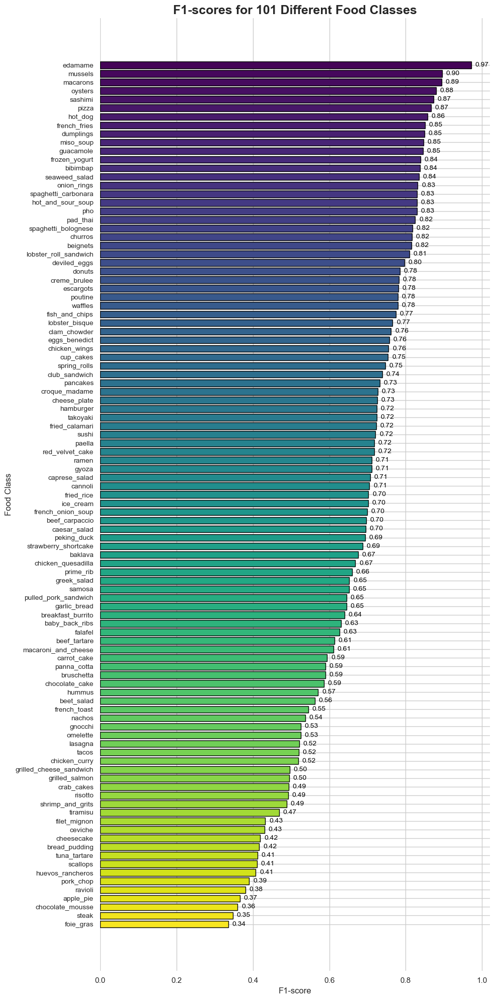

In [31]:
fig, ax = plt.subplots(figsize=(10, 20))

colors = sns.color_palette("viridis", len(f1_scores))

bars = ax.barh(
    y=range(len(f1_scores)),
    width=f1_scores["f1-score"].values,
    color=colors,
    edgecolor='black'
)

for i, bar in enumerate(bars):
    score = f1_scores["f1-score"].values[i]
    ax.text(score + 0.01, bar.get_y() + bar.get_height() / 2,
            f"{score:.2f}", va='center', fontsize=10, color='black')

ax.set_yticks(range(len(f1_scores)))
ax.set_yticklabels(f1_scores["class_names"], fontsize=10)

ax.set_title("F1-scores for 101 Different Food Classes", fontsize=18, fontweight='bold')
ax.set_xlabel("F1-score", fontsize=12)
ax.set_ylabel("Food Class", fontsize=12)

ax.invert_yaxis()

sns.despine(left=True, bottom=True)

plt.tight_layout()
plt.show()


## Wizualizacja prognoz na testowych obrazach

Aby zwizualizować prognozy mojego modelu na własnych/testowych obrazach, potrzebuję funkcji do ładowania i wstępnego przetwarzania obrazów. Funkcja ta powinna:
* Wczytać obraz z podanej ścieżki za pomocą `tf.io.read_file()`
* Zmienić rozmiar obrazu, aby odpowiadał wymiarom obrazów, na których model był trenowany, za pomocą `tf.image.resize()`
* Przeskalować obraz, aby wszystkie wartości pikseli znajdowały się w zakresie od 0 do 1 (jeśli to konieczne)

W tym celu stworzyłem funkcję load_and_prep_image(), która umożliwia załadowanie obrazu z dysku, jego odpowiednie przeskalowanie do wymaganych wymiarów oraz ewentualne przeskalowanie wartości pikseli do zakresu od 0 do 1. Funkcja ta jest używana do przygotowania obrazów przed ich wprowadzeniem do modelu w celu dokonania prognoz.

1/1 [==============================] - 5s 5s/step


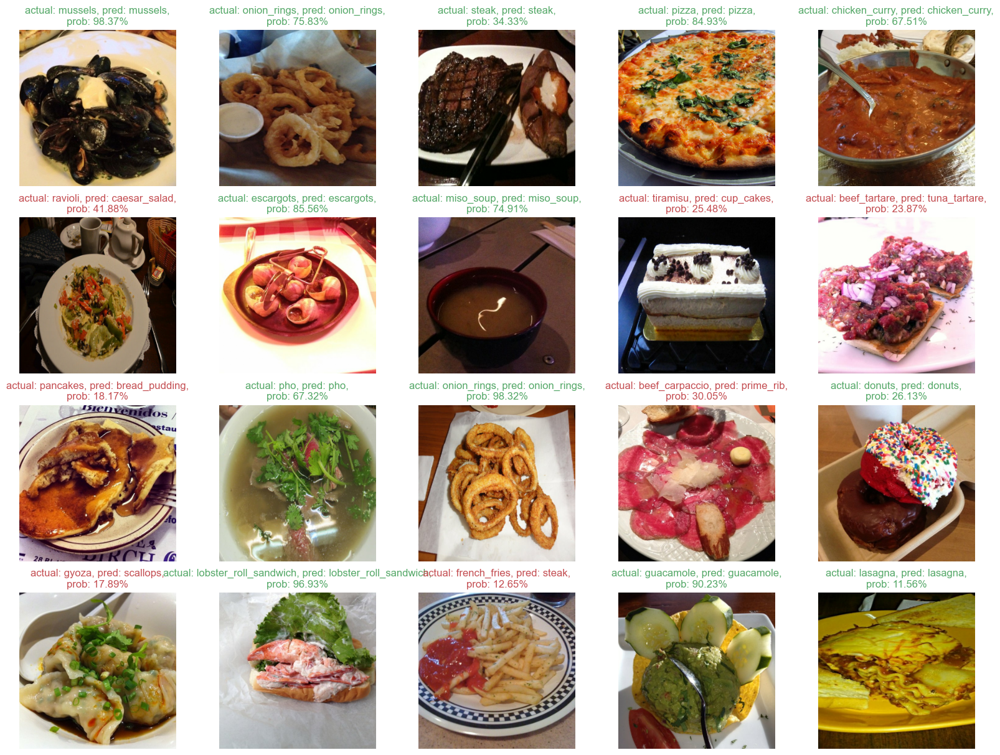

In [45]:
plt.figure(figsize=(20, 15))
for i in range (20):
    class_name = random.choice(class_names)
    file_name = random.choice(os.listdir(test_dir + '/' + class_name))
    file_path = test_dir + class_name + "/" + file_name

    img = load_and_prep_image(file_path, scale=False)
    img_expanded = tf.expand_dims(img, axis=0)
    pred_prob = model.predict(img_expanded)
    pred_class = class_names[pred_prob.argmax()]

    plt.subplot(4, 5, i+1)
    plt.imshow(img/255.)
    if class_name == pred_class:
        title_color = 'g'
    else:
        title_color = 'r'
    plt.title(f'actual: {class_name}, pred: {pred_class},\nprob: {pred_prob.max()*100:.2f}%', c=title_color)
    plt.axis(False);

## Znajdowanie najbardziej błędnych prognoz

Aby dowiedzieć się, gdzie model popełnia największe błędy, wykonam następujące kroki:

1. **Pobieram wszystkie ścieżki plików obrazów w zbiorze testowym** za pomocą metody `list_files()`.
2. **Stwórzę DataFrame**, który zawiera:
   - Ścieżki plików obrazów
   - Rzeczywiste etykiety klas
   - Przewidywane etykiety klas
   - Maksymalne prawdopodobieństwa prognoz
3. **Znajdę błędne prognozy** w ramce danych (gdzie prawdziwa etykieta nie zgadza się z przewidywaną klasą).
4. **Posortuję ramkę danych** według błędnych prognoz (z najwyższym prawdopodobieństwem prognozy na górze).
5. **Wizualizuję obrazy** z najwyższymi prawdopodobieństwami błędnych prognoz.

In [33]:
# 1.
filepaths = []
for filepath in test_data.list_files('101_food_classes_10_percent/test/*/*.jpg', shuffle=False):
    filepaths.append(filepath.numpy())
filepaths[:10]

[b'101_food_classes_10_percent/test/apple_pie/1011328.jpg',
 b'101_food_classes_10_percent/test/apple_pie/101251.jpg',
 b'101_food_classes_10_percent/test/apple_pie/1034399.jpg',
 b'101_food_classes_10_percent/test/apple_pie/103801.jpg',
 b'101_food_classes_10_percent/test/apple_pie/1038694.jpg',
 b'101_food_classes_10_percent/test/apple_pie/1047447.jpg',
 b'101_food_classes_10_percent/test/apple_pie/1068632.jpg',
 b'101_food_classes_10_percent/test/apple_pie/110043.jpg',
 b'101_food_classes_10_percent/test/apple_pie/1106961.jpg',
 b'101_food_classes_10_percent/test/apple_pie/1113017.jpg']

In [34]:
# 2.
pred_df = pd.DataFrame({'img_path': filepaths,
                        'y_true': y_labels,
                        'y_pred': pred_classes,
                        'pred_conf': preds_probs.max(axis=1),
                        'y_true_classname': [class_names[i] for i in y_labels],
                        'y_pred_classname': [class_names[i] for i in pred_classes]})

pred_df.head()

,img_path,y_true,y_pred,pred_conf,y_true_classname,y_pred_classname
0,b'101_food_classes_10_percent/test/apple_pie/1...,0,85,0.722055,apple_pie,samosa
1,b'101_food_classes_10_percent/test/apple_pie/1...,0,0,0.853749,apple_pie,apple_pie
2,b'101_food_classes_10_percent/test/apple_pie/1...,0,0,0.598940,apple_pie,apple_pie
3,b'101_food_classes_10_percent/test/apple_pie/1...,0,0,0.448909,apple_pie,apple_pie
4,b'101_food_classes_10_percent/test/apple_pie/1...,0,0,0.423818,apple_pie,apple_pie


In [35]:
# 3.
pred_df['pred_correct'] = pred_df['y_true'] == pred_df['y_pred']
pred_df.head()

,img_path,y_true,y_pred,pred_conf,y_true_classname,y_pred_classname,pred_correct
0,b'101_food_classes_10_percent/test/apple_pie/1...,0,85,0.722055,apple_pie,samosa,False
1,b'101_food_classes_10_percent/test/apple_pie/1...,0,0,0.853749,apple_pie,apple_pie,True
2,b'101_food_classes_10_percent/test/apple_pie/1...,0,0,0.598940,apple_pie,apple_pie,True
3,b'101_food_classes_10_percent/test/apple_pie/1...,0,0,0.448909,apple_pie,apple_pie,True
4,b'101_food_classes_10_percent/test/apple_pie/1...,0,0,0.423818,apple_pie,apple_pie,True


In [36]:
# 4.
top_100_wrong = pred_df[pred_df['pred_correct'] == False].sort_values('pred_conf', ascending=False)[:100]
top_100_wrong.head(20)

,img_path,y_true,y_pred,pred_conf,y_true_classname,y_pred_classname,pred_correct
22684,b'101_food_classes_10_percent/test/spaghetti_b...,90,91,0.991970,spaghetti_bolognese,spaghetti_carbonara,False
16271,b'101_food_classes_10_percent/test/mussels/140...,65,69,0.987688,mussels,oysters,False
14482,b'101_food_classes_10_percent/test/hummus/8476...,57,51,0.986646,hummus,guacamole,False
17908,b'101_food_classes_10_percent/test/paella/3192...,71,65,0.979166,paella,mussels,False
3760,b'101_food_classes_10_percent/test/ceviche/119...,15,48,0.973368,ceviche,greek_salad,False
16151,b'101_food_classes_10_percent/test/miso_soup/3...,64,54,0.969253,miso_soup,hot_and_sour_soup,False
25166,b'101_food_classes_10_percent/test/waffles/335...,100,42,0.967015,waffles,french_toast,False
14723,b'101_food_classes_10_percent/test/ice_cream/6...,58,45,0.966751,ice_cream,frozen_yogurt,False
4737,b'101_food_classes_10_percent/test/chicken_cur...,18,60,0.961942,chicken_curry,lobster_bisque,False
10948,b'101_food_classes_10_percent/test/fried_calam...,43,31,0.960859,fried_calamari,donuts,False


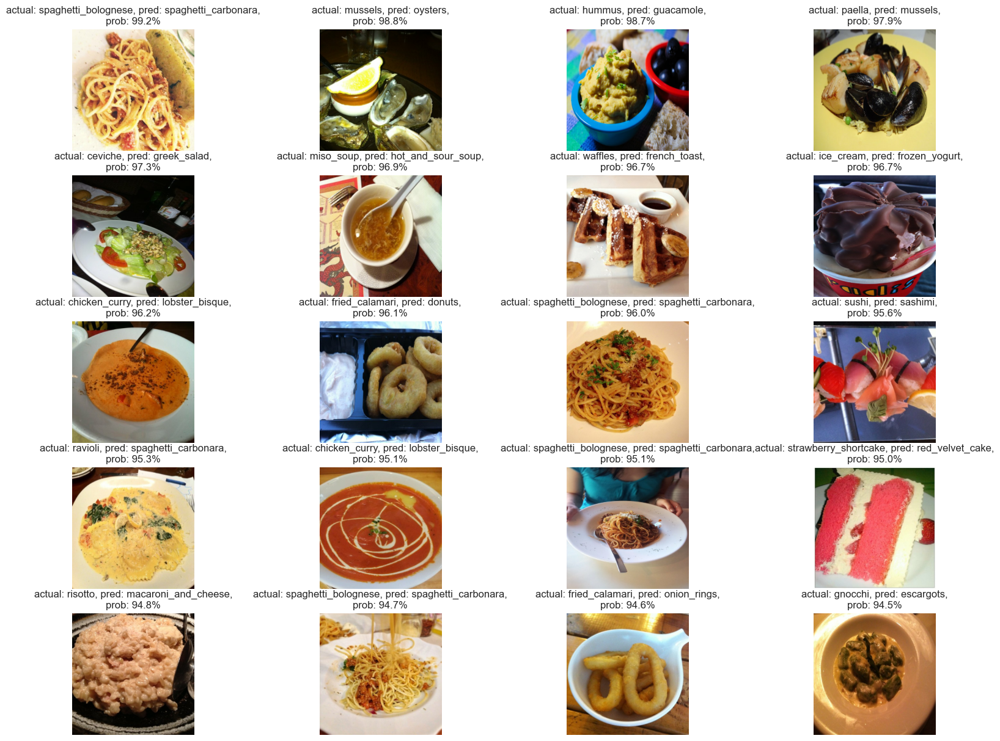

In [50]:
# 5.
images_to_view = 20
start_index = 0
plt.figure(figsize=(20, 15))
for i, row in enumerate(top_100_wrong.iloc[start_index:start_index + images_to_view].itertuples()):
    plt.subplot(5, 4, i+1)
    img = load_and_prep_image(row[1], scale=False)
    _, _, _, _, pred_prob, y_true_classname, y_pred_classname, _ = row
    plt.imshow(img/255.)
    plt.title(f'actual: {y_true_classname}, pred: {y_pred_classname},\nprob: {pred_prob*100:.1f}%')
    plt.axis(False)


## Testowanie modelu na własnych zdjęciach jedzenia

In [41]:
custom_food_images = ['custom_food_images/' + img_path for img_path in os.listdir('custom_food_images')]
custom_food_images

['custom_food_images/spaghetti.jpg',
 'custom_food_images/hotdog.jpg',
 'custom_food_images/churros.jpg',
 'custom_food_images/applepie.jpeg',
 'custom_food_images/chiecken_wings.jpg',
 'custom_food_images/ramen.jpg',
 'custom_food_images/sushi.jpg',
 'custom_food_images/pizza.jpg',
 'custom_food_images/burger.jpeg']

1/1 [==============================] - 3s 3s/step


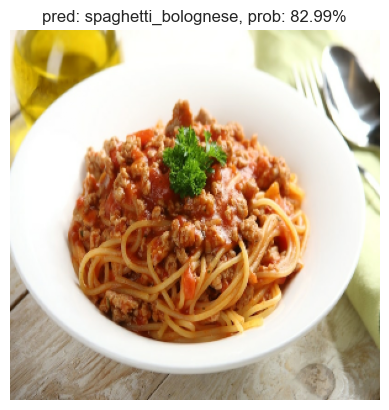

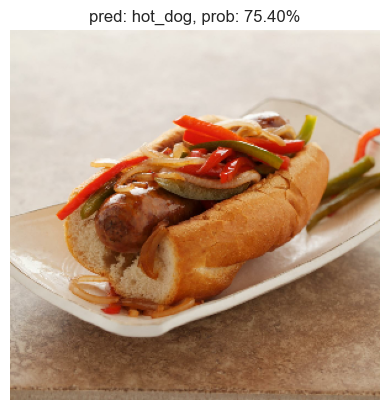

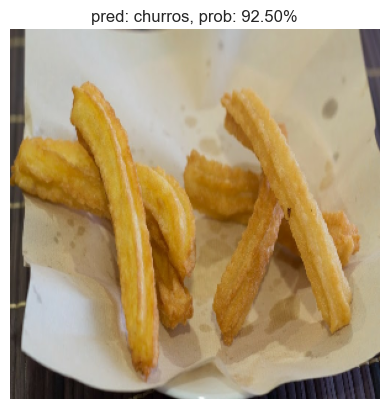

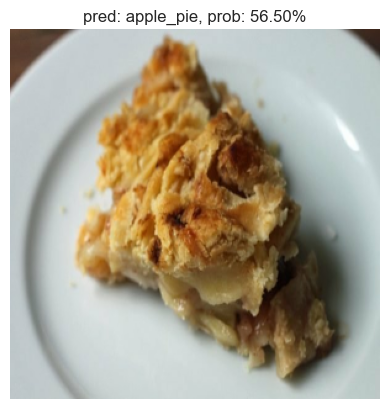

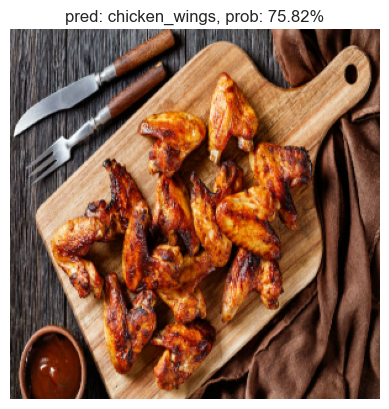

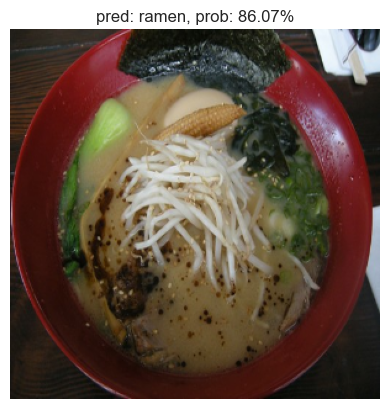

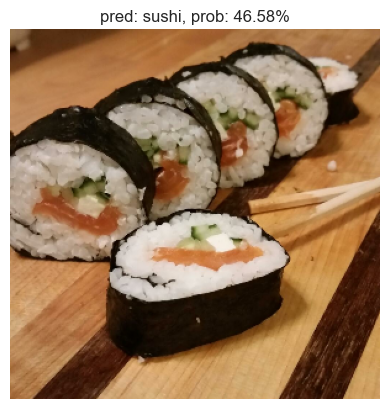

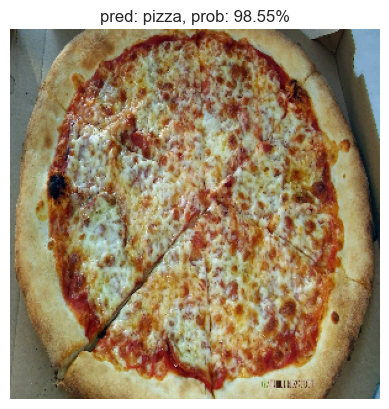

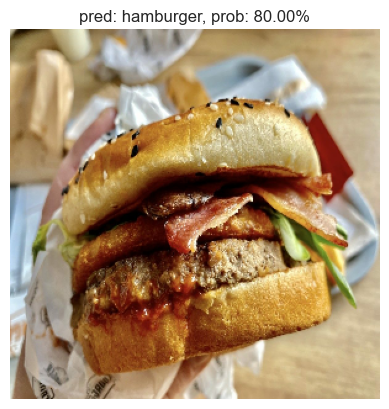

In [42]:
for img in custom_food_images:
    img = load_and_prep_image(img, scale=False)
    pred_prob = model.predict(tf.expand_dims(img, axis=0))
    pred_class = class_names[pred_prob.argmax()]

    plt.figure()
    plt.imshow(img/255.)
    plt.title(f'pred: {pred_class}, prob: {pred_prob.max()*100:.2f}%')
    plt.axis(False)